<h1 style="text-align: center;">02 Data Communication</h1>
<hr>


## **12. Synchronization and Framing**

<div class="alert alert-light">

  **Name:** Stefan Sykes
  
  **Matriculation Number:** 11-250-693

</div>


### 12.1 From Continuous Audio to Symbols

The FSK detector in notebook 02.11 compared the energy at a set of known frequencies within each symbol interval. Those experiments supplied the exact beginning and duration of every symbol. A real receiver, however, observes a continuous stream of samples that may include silence, background noise, and several transmissions. Before decoding, it must locate the beginning and end of a transmission and divide the enclosed data into correctly aligned symbol intervals. Locating the transmission is a framing problem; aligning the measurement windows is a synchronization problem.

The experiment below isolates the effect of an incorrectly aligned window. The transmitted frequencies and symbol duration are known, but the detector begins its first measurement too late. The grey boundaries mark the transmitted symbols, while the red boundaries show the receiver's measurement windows. Moving the offset slider reveals how a timing error changes the measured tone energies and the resulting bit decisions.


In [1]:
%matplotlib inline

from pathlib import Path
import sys

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import IntSlider, FloatSlider
from IPython.display import Audio, display

for _root in (Path.cwd(), *Path.cwd().parents):
    ACOUSTIC_SUPPORT = _root / ".admin" / "acoustic_workshop"
    if (ACOUSTIC_SUPPORT / "acoustic.py").is_file():
        break
else:
    raise FileNotFoundError("Start Jupyter from inside the MobileComputing repository.")

if str(ACOUSTIC_SUPPORT) not in sys.path:
    sys.path.insert(0, str(ACOUSTIC_SUPPORT))

import acoustic as ac

ACOUSTIC_ASSETS = ACOUSTIC_SUPPORT / "assets"

rate = ac.SAMPLE_RATE
WIDE = {"description_width": "initial"}

demo_tones = np.array([600.0, 900.0])
demo_bits = np.array([1, 0, 1, 1, 0, 0, 1, 0], dtype=np.uint8)
symbol_ms = 40
demo_wave = ac.modulate(demo_bits, demo_tones, symbol_ms, rate)
per_symbol = int(rate * symbol_ms / 1000)

def make_offset_figure(offset_ms):
    offset = int(round(offset_ms / 1000 * rate))
    padded = np.concatenate([demo_wave, np.zeros(2 * per_symbol)])
    energies = ac.tone_energies(
        padded, rate, demo_tones, offset, len(demo_bits), symbol_ms)
    decided = ac.demodulate(energies)
    correct = int(np.sum(decided == demo_bits))

    figure, axes = plt.subplots(2, 1, figsize=(11, 5.2))
    time_ms = np.arange(len(demo_wave)) / rate * 1000
    axes[0].plot(time_ms, demo_wave, linewidth=0.65, color="0.25")

    for boundary in np.arange(len(demo_bits) + 1) * symbol_ms:
        axes[0].axvline(boundary, color="0.82", linewidth=0.8)
    for boundary in offset_ms + np.arange(len(demo_bits) + 1) * symbol_ms:
        axes[0].axvline(boundary, color="tab:red", linestyle="--",
                        linewidth=0.7)

    axes[0].set(xlim=(0, len(demo_bits) * symbol_ms), ylim=(-0.65, 0.65),
                xlabel="Time (ms)", ylabel="Amplitude",
                title="Grey: transmitted symbols   Red: receiver windows")

    for column, frequency in enumerate(demo_tones):
        axes[1].plot(energies[:, column], marker="o", linewidth=1.0,
                     label=f"{frequency:.0f} Hz")
    axes[1].set(xlabel="Receiver window", ylabel="Measured tone energy")
    axes[1].legend(fontsize=8)
    axes[1].grid(alpha=0.25)

    figure.suptitle(
        f"Receiver starts {offset_ms} ms late "
        f"({offset_ms / symbol_ms:.2f} symbol)  ·  {correct}/{len(demo_bits)} correct")
    figure.tight_layout()
    return figure


IntSlider(value=0, continuous_update=False, description='Start late by (ms)', max=40, style=SliderStyle(descri…

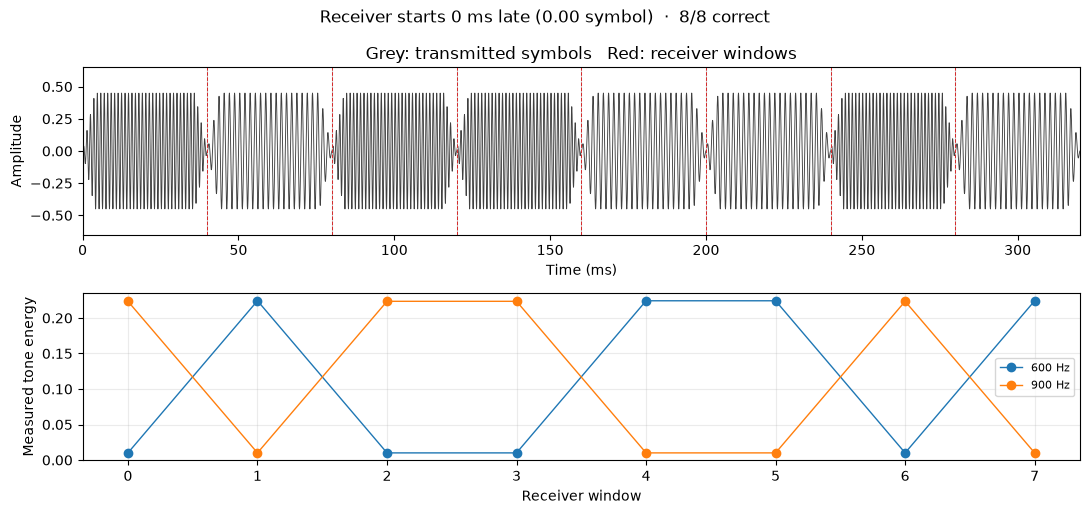

In [2]:
offset_slider = IntSlider(min=0, max=40, step=1, value=0,
                          description="Start late by (ms)",
                          continuous_update=False, style=WIDE)
display(offset_slider)

offset_figure = make_offset_figure(offset_slider.value)
offset_handle = display(offset_figure, display_id=True)
plt.close(offset_figure)

def update_offset_plot(change=None):
    offset_figure = make_offset_figure(offset_slider.value)
    offset_handle.update(offset_figure)
    plt.close(offset_figure)

offset_slider.observe(update_offset_plot, names="value")


When the receiver windows align with the transmitted symbols, each window contains a single tone, and its measured energy is clearly larger than that of the other candidate. As the offset increases, a window overlaps two consecutive symbols. If those symbols use different tones, both contribute energy to the measurement, making the decision less clear and potentially changing the decoded bit. Consecutive symbols that use the same tone do not create this ambiguity.

Knowing the correct frequencies is therefore only part of the receiver's task. Reliable detection also requires synchronization in time. The next section introduces chirps, frequency sweeps that can serve as recognizable timing markers.


### 12.2 Chirps in Nature and Technology

A **chirp** is a signal whose frequency changes over time. An **up-chirp** sweeps from lower to higher frequencies, while a **down-chirp** sweeps in the opposite direction. For an audible chirp, this produces a rising or falling pitch. In a spectrogram, the sweep appears as a sloping line rather than the horizontal line of a constant tone. A linear chirp changes frequency at a constant rate; other chirps can follow curved frequency sweeps.

Bat echolocation provides a natural example. Many bats emit short, ultrasonic calls containing frequency sweeps and listen for echoes from objects around them. For example, the pallid bat uses downward frequency sweeps for orientation and obstacle avoidance, as described in this [study of its echolocation calls](https://pubmed.ncbi.nlm.nih.gov/28275715/). The delay between a call and its returning echo provides information about distance: a longer delay corresponds to a longer journey to the object and back. Bat calls vary with species and task, so a simple linear chirp is a useful illustration rather than a complete model of every call.

Engineered radar systems also use chirps, transmitted as electromagnetic waves. A receiver compares the returning echo with the known transmitted waveform to locate it in time. **Pulse compression** makes a longer chirped pulse produce a narrow detection peak, combining energy collected over the pulse with precise timing. For example, the [radar on ESA's ERS satellites](https://www.esa.int/esapub/bulletin/bullet83/fran83.htm) uses a linear chirp and matched filtering for this purpose. Once an echo delay is known, the distance follows from the wave's propagation speed and its round trip to the target.

> **Why use a linear chirp instead of another known sound?**
>
> Any known sound can serve as a reference for detection. A constant tone, however, repeats the same cycles, so several time shifts can produce similar correlation scores. A chirp sweeps through frequencies in a defined order. Shifting it in time misaligns that pattern, producing a more distinct correlation peak at the correct arrival time.
>
> A chirp can last long enough to carry substantial energy while still producing a narrow correlation peak. This combines detection in noise with precise timing: the principle of **pulse compression** used in radar. The duration controls how much energy can be transmitted at a given power, while the swept bandwidth strongly influences the width of the correlation peak. See [ESA's description of chirps and matched filtering in the ERS radar](https://www.esa.int/esapub/bulletin/bullet83/fran83.htm).
>
> Linearity is a convenient design choice, not a requirement for reliable detection. Another carefully chosen waveform, including a known noise sequence, can also work well. A linear chirp is useful because it is easy to generate and reproduce, with a controllable duration and frequency range.

In this notebook, chirps provide recognizable timing markers for communication. The receiver searches for a known frequency sweep in the incoming sound to locate the start of a message. The same connection between a distinctive waveform and its arrival time underlies the examples above, although the biological and engineered processing methods differ. The next section shows how cross-correlation performs this search for an acoustic preamble.


### 12.3 Detecting a Known Preamble with Cross-Correlation

A **preamble** is a known signal placed before the data so that the receiver can recognize the start of a transmission. Here, the preamble is a 0.5 s **up-chirp** whose frequency rises from 300 Hz to 3000 Hz. Rather than searching for an arbitrary increase in sound level, the receiver searches for this specific pattern.

Cross-correlation, introduced in notebook 01.6, provides a way to locate one signal inside another. Let $p[n]$ represent the known chirp and $x[n]$ the longer recording containing it at an unknown time. The receiver shifts the reference chirp to each candidate starting position $k$ and calculates

$$c[k] = \sum_n x[n+k]p[n].$$

At each position, corresponding samples are multiplied and the products are added over the duration of the chirp. When the reference aligns with the received chirp, the two waveforms follow a similar pattern. Their products are mostly positive and add to a large value. At incorrect positions, positive and negative products tend to cancel. The position of the correlation peak therefore provides an estimate of the chirp's starting time.

The figure presents this process in three panels: the known chirp, the longer recording, and their cross-correlation. The signal-to-noise ratio (SNR) slider changes the noise in the recording, making it possible to compare the visual appearance of the chirp with the strength and position of the correlation peak.


In [3]:
chirp = ac.make_chirp(rate)
CHIRP_AT_S = 1.50
chirp_start_sample = int(CHIRP_AT_S * rate)

clean_recording = np.zeros(int(3.2 * rate))
clean_recording[chirp_start_sample:chirp_start_sample + len(chirp)] = chirp

print(f"Known preamble: frequency rises from {ac.CHIRP_START_HZ:.0f} Hz "
      f"to {ac.CHIRP_END_HZ:.0f} Hz in {ac.CHIRP_DURATION_S:.2f} s")
display(Audio(chirp, rate=rate))

def make_preamble_figure(snr_db):
    recording = ac.add_noise(
        clean_recording, rate, snr_db=float(snr_db), seed=3)
    correlation = ac.matched_filter(recording, chirp)
    found_sample = int(np.argmax(correlation))
    found_s = found_sample / rate
    error_ms = 1000 * (found_s - CHIRP_AT_S)

    figure, axes = plt.subplots(3, 1, figsize=(11, 7.2))

    axes[0].specgram(chirp, NFFT=1024, Fs=rate, noverlap=768,
                     cmap="magma")
    axes[0].set(xlim=(0, len(chirp) / rate), ylim=(0, 3500),
                ylabel="Frequency (Hz)",
                title="$p[n]$: known rising chirp to detect")

    axes[1].specgram(recording, NFFT=1024, Fs=rate, noverlap=768,
                     cmap="magma")
    axes[1].axvline(CHIRP_AT_S, color="cyan", linestyle="--",
                    label="chirp begins")
    axes[1].set(xlim=(0, len(recording) / rate), ylim=(0, 3500),
                ylabel="Frequency (Hz)",
                title="$x[n]$: longer recording containing the same chirp")
    axes[1].legend(fontsize=8)

    tested_positions = np.arange(len(correlation)) / rate
    match_scale = max(0.1, min(1.0, 1.08 * float(correlation.max())))
    # Keep every sample so narrow peaks are not skipped in the plotted curve.
    axes[2].plot(tested_positions, correlation,
                 linewidth=0.8, color="tab:blue")
    axes[2].scatter(found_s, correlation[found_sample], color="tab:blue",
                    s=28, zorder=3, label="Maximum correlation")
    axes[2].set(xlim=(0, tested_positions[-1]), ylim=(0, match_scale),
                xlabel="Tested starting position $k$ (s)", ylabel="Match",
                title=f"Cross-correlation peak at {found_s:.3f} s "
                      f"({error_ms:+.1f} ms error, match {correlation[found_sample]:.2f})")
    axes[2].legend(fontsize=8)
    axes[2].grid(alpha=0.2)

    figure.suptitle(f"Finding the known up-chirp at SNR = {snr_db} dB")
    figure.tight_layout()
    return figure


Known preamble: frequency rises from 300 Hz to 3000 Hz in 0.50 s


IntSlider(value=0, continuous_update=False, description='SNR (dB)', max=10, min=-40, style=SliderStyle(descrip…

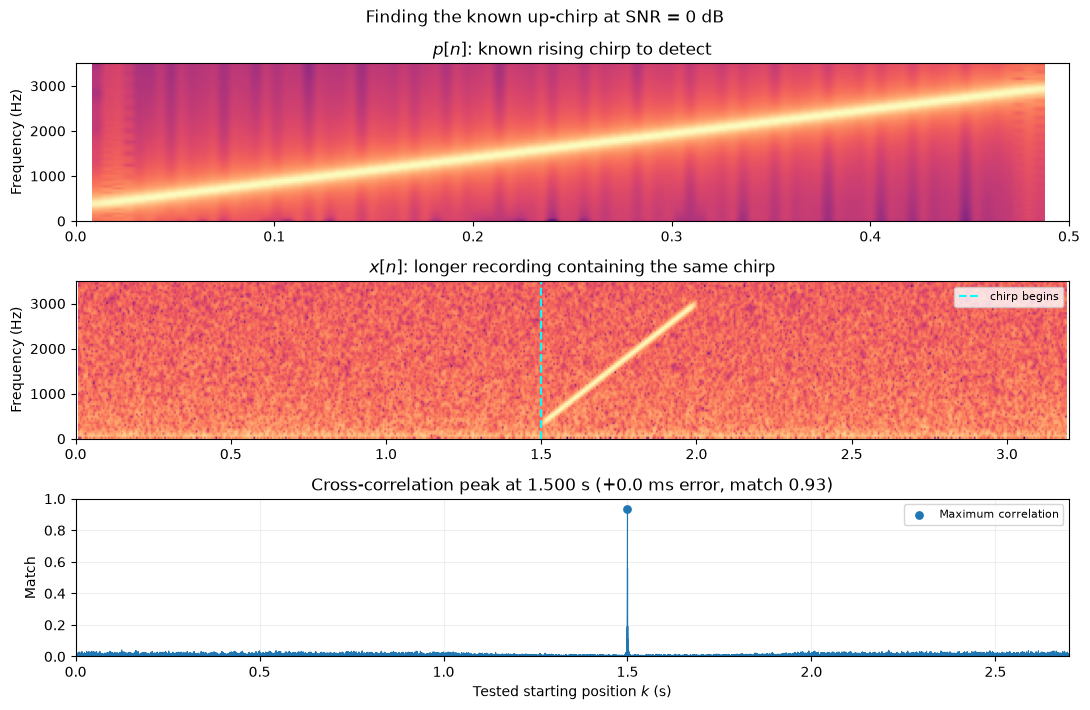

In [4]:
preamble_snr_slider = IntSlider(
    min=-40, max=10, step=1, value=0,
    description="SNR (dB)", continuous_update=False, style=WIDE)
display(preamble_snr_slider)

preamble_figure = make_preamble_figure(preamble_snr_slider.value)
preamble_handle = display(preamble_figure, display_id=True)
plt.close(preamble_figure)

def update_preamble_plot(change=None):
    preamble_figure = make_preamble_figure(preamble_snr_slider.value)
    preamble_handle.update(preamble_figure)
    plt.close(preamble_figure)

preamble_snr_slider.observe(update_preamble_plot, names="value")


At 0 dB SNR, the rising line in the received spectrogram begins at 1.5 s, and the correlation plot reaches its maximum at the same position. Lowering the SNR makes the chirp harder to distinguish visually. Its correlation peak can remain identifiable because the receiver combines evidence from the complete 0.5 s pattern rather than relying on individual samples.

The changing frequency makes a chirp particularly useful as a preamble. A constant tone repeats the same cycle, so several nearby shifts can produce similar matches. A rising chirp has a changing pattern across its duration, producing a more distinct alignment peak. At sufficiently high noise levels, however, an incorrect position can produce the largest peak, so the peak position matters as well as its height. The plotted match uses a normalized scale between 0 and 1 to make the results easier to compare.


### 12.4 The Complete Frame

Detecting the starting chirp identifies the beginning of a transmission, but the receiver also needs to know where the message ends. The acoustic link therefore surrounds the data with two different chirps, forming a **frame**:

```text
[ silence ][ up-chirp ][ gap ][ ASCII message ][ gap ][ down-chirp ][ silence ]
```

The up-chirp marks the beginning, while the down-chirp marks the end. Their opposite frequency sweeps allow the receiver to search for each boundary separately. The gaps separate these markers from the data region, or **payload**, which carries the ASCII message using the eight FSK tones studied in notebook 02.11.

This frame has no header containing a message length or identifier. Instead, the down-chirp tells the receiver where the data region ends. Another protocol could announce the payload length in a header and use that value to determine how much data to receive. Both approaches give the receiver information that the continuous audio stream alone does not provide: where one message stops.


### 12.5 Seeing the Frame

The following cells generate a practice frame and simulate its passage through a noisy acoustic channel. In the spectrogram, the up-chirp appears as a rising line, the data as a sequence of horizontal FSK tones, and the down-chirp as a falling line. These shapes connect the frame structure above to the sound received by the microphone.

The spectrogram window controls the trade-off between time and frequency resolution. A short window makes transitions easier to locate in time, but spreads each tone over a wider frequency range. A long window separates nearby frequencies more clearly, but blurs the timing of transitions. Adjusting the window shows why one spectrogram setting may reveal the frame boundaries more clearly while another makes the individual data tones easier to distinguish.

The spectrogram provides a visual interpretation of the frame. The receiver uses correlation with the two known chirps to locate its boundaries more precisely, as shown in the correlation plot that follows.


In [5]:
practice = ac.encode("PRACTICE FRAME")
practice.describe()
display(Audio(practice.samples, rate=rate))

received = ac.simulate_channel(practice.samples, rate, snr_db=15)
practice_burst = ac.find_burst(received, rate)

def make_window_figure(window_ms):
    return ac.plot_spectrogram(
        received, rate, window_ms=window_ms, max_hz=3600,
        title=f"A complete frame, seen through a {window_ms} ms window")


message    'PRACTICE FRAME'
  8-FSK, 3 bits per symbol
  tones     937.5 .. 2250.0 Hz, spacing 187.50 Hz
  symbol    40.0 ms  ->  75 bit/s
  duration  3.07 s


IntSlider(value=12, continuous_update=False, description='Spectrogram window (ms)', max=80, min=2, step=2, sty…

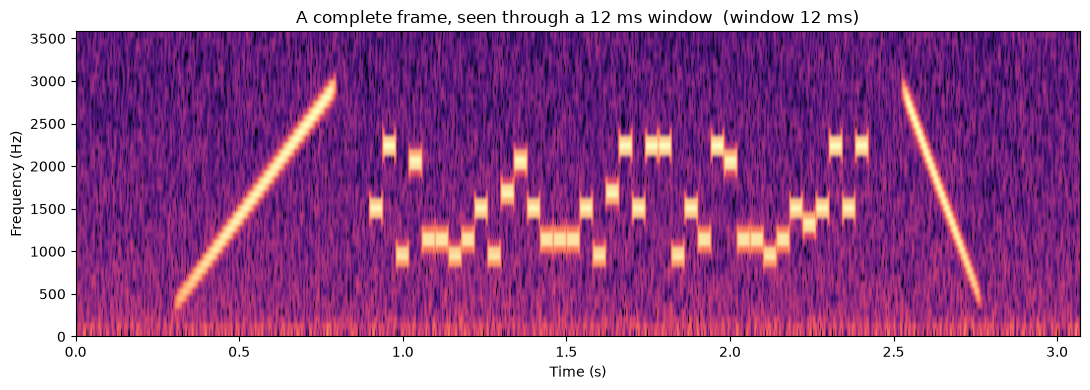

In [6]:
window_slider = IntSlider(min=2, max=80, step=2, value=12,
                          description="Spectrogram window (ms)",
                          continuous_update=False, style=WIDE)
display(window_slider)

window_figure = make_window_figure(window_slider.value)
window_handle = display(window_figure, display_id=True)
plt.close(window_figure)

def update_window_plot(change=None):
    window_figure = make_window_figure(window_slider.value)
    window_handle.update(window_figure)
    plt.close(window_figure)

window_slider.observe(update_window_plot, names="value")


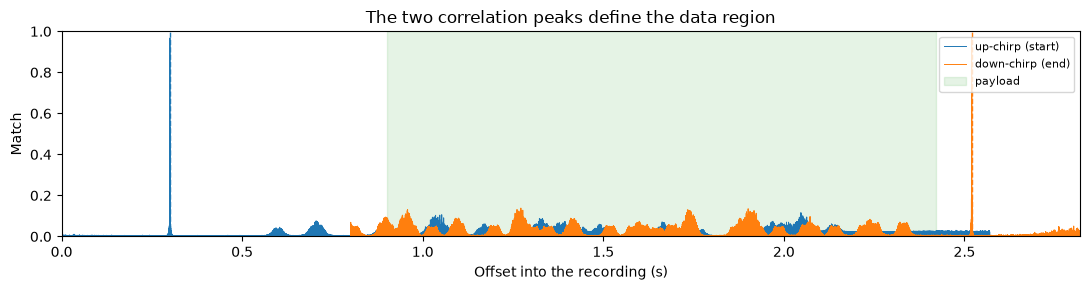

In [7]:
practice_correlation = ac.plot_correlation(
    practice_burst, title="The two correlation peaks define the data region")


### 12.6 How Long Is a Symbol?

Once the two chirps have been located, the receiver can isolate the data region. This establishes where to look, but it does not yet specify how long each symbol lasts. The detector must choose a symbol duration before dividing the data into measurement windows and comparing the candidate tone energies.

An incorrect duration causes the receiver's boundaries to drift relative to the transmitted boundaries. Even if the first window begins at the correct position, later windows can overlap adjacent symbols. Their energy measurements then mix contributions from different tones, and the decoded text becomes less reliable. This differs from the fixed offset in Section 12.1: a duration error accumulates as the receiver advances through the message.

Try assumed durations of 25 ms, 40 ms, and 55 ms in the experiment below. Compare how clearly the strongest tone stands out from the other candidates, how closely the data region fits a whole number of symbols, and whether the resulting text is readable. These observations provide complementary evidence for choosing a duration.


In [8]:
practice_burst.describe()

def make_guess_figure(guess_ms):
    result = ac.decode(received, rate, symbol_ms=guess_ms, burst=practice_burst)
    ordered = np.sort(result.energies, axis=1)
    margin = np.mean(
        (ordered[:, -1] - ordered[:, -2]) / (ordered[:, -1] + 1e-12))
    fit = ac.whole_symbol_fit(practice_burst.sample_count, guess_ms, rate)
    shown = ac.readable(result.text)[:28]
    return ac.plot_symbol_energies(
        result.energies, ac.payload_tones(), max_symbols=32,
        title=f"T = {guess_ms:.1f} ms  ·  tone margin {margin:.0%}  ·  "
              f"whole-symbol fit {fit:.2f}  ·  {shown!r}")


up-chirp    at   0.300 s   match 0.97
down-chirp  at   2.520 s   match 0.97
payload       0.900 s .. 2.420 s   (1.520 s, 72960 samples)


FloatSlider(value=40.0, continuous_update=False, description='Assumed symbol length (ms)', max=70.0, min=15.0,…

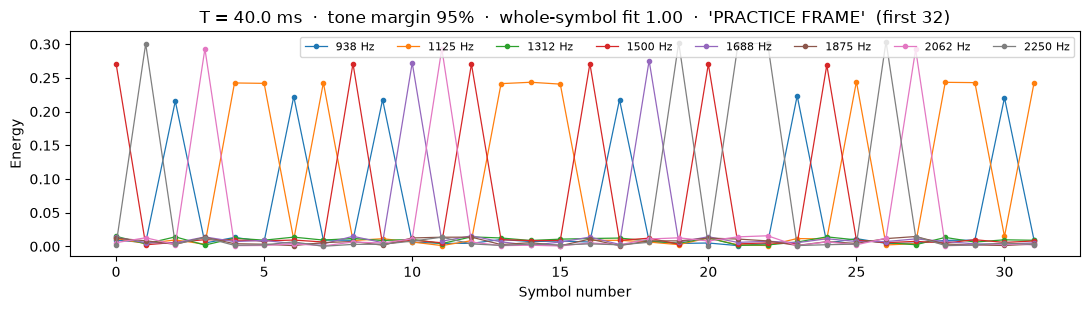

In [ ]:
guess_slider = FloatSlider(min=15.0, max=70.0, step=0.5, value=40.0,
                           description="Assumed symbol length (ms)", readout_format=".1f",
                           continuous_update=False, style=WIDE)
display(guess_slider)

guess_figure = make_guess_figure(guess_slider.value)
guess_handle = display(guess_figure, display_id=True)
plt.close(guess_figure)

def update_guess_plot(change=None):
    guess_figure = make_guess_figure(guess_slider.value)
    guess_handle.update(guess_figure)
    plt.close(guess_figure)

guess_slider.observe(update_guess_plot, names="value")


A suitable duration aligns the measurement windows with the transmitted symbols, producing well-separated tone energies and a data region that contains a whole number of symbols. The search below automates the comparison: `ac.search_symbol_ms` tests candidate durations and favours results that fit the frame and produce readable ASCII.

Readable text is useful evidence for this exercise because the payload is known to contain an ASCII message. It is not a general synchronization method, and these measurements may not identify every unknown signal uniquely. Practical communication systems usually specify the symbol duration in advance or announce the selected **modulation and coding scheme (MCS)** in a robust header. This shared information reduces the number of possibilities the receiver must test.


best symbol duration 40.00 ms   (score 100.0%)
8-FSK   base 937.5 Hz   spacing 187.50 Hz   symbol 40.00 ms
14 bytes, 100.0% printable
message     'PRACTICE FRAME'


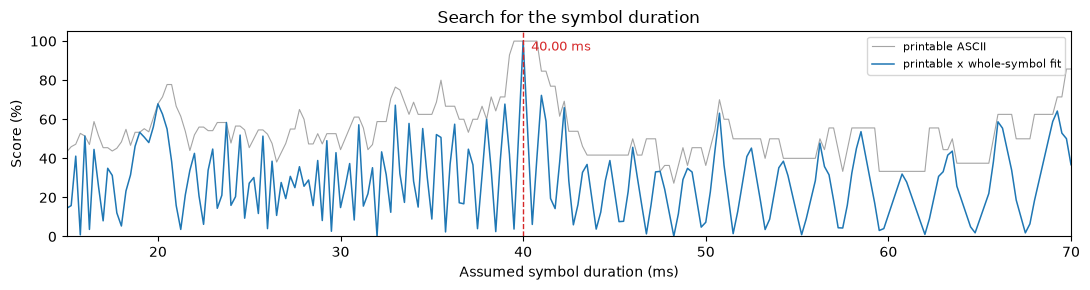

In [10]:
practice_search = ac.search_symbol_ms(
    received, rate, burst=practice_burst,
    low_ms=15.0, high_ms=70.0, step_ms=0.25)
practice_search_figure = ac.plot_search(
    practice_search, title="Search for the symbol duration")
practice_search.describe()


### 12.7 Decode the Secret Message

The recording in `secret_message.wav` can now be examined with a complete receiver chain. The first code cell searches for the up-chirp and down-chirp and uses their positions to isolate the data region. The next cell computes a spectrum of that region and identifies the FSK tone frequencies, applying the method introduced in notebook 02.11. The final cell searches for the symbol duration and uses the resulting measurement windows to decode the symbols into text.

Each stage supplies information needed by the next. Correlation determines **when** to analyse the recording, the spectrum determines **which frequencies** to test, and the duration search determines **how long** each measurement should last. Run the cells in order and relate the reported values to the figures, following the signal from its frame boundaries through to the recovered message.


up-chirp    at   1.500 s   match 0.92
down-chirp  at   6.960 s   match 0.92
payload       2.100 s .. 6.860 s   (4.760 s, 228480 samples)


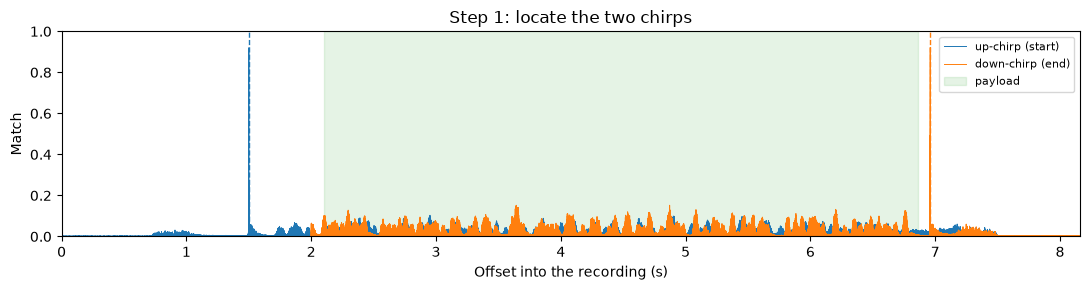

In [11]:
secret, secret_rate = ac.load_wav(ACOUSTIC_ASSETS / "secret_message.wav")

# 1. Locate the beginning and end of the frame.
secret_burst = ac.find_burst(secret, secret_rate)
secret_burst.describe()
burst_figure = ac.plot_correlation(
    secret_burst, title="Step 1: locate the two chirps")


tones    1114.3, 1371.4, 1590.5, 1828.6, 2057.1, 2305.3, 2528.6, 2771.4 Hz
base     1114.3 Hz
spacing  236.7 Hz (spread 12.8 Hz)


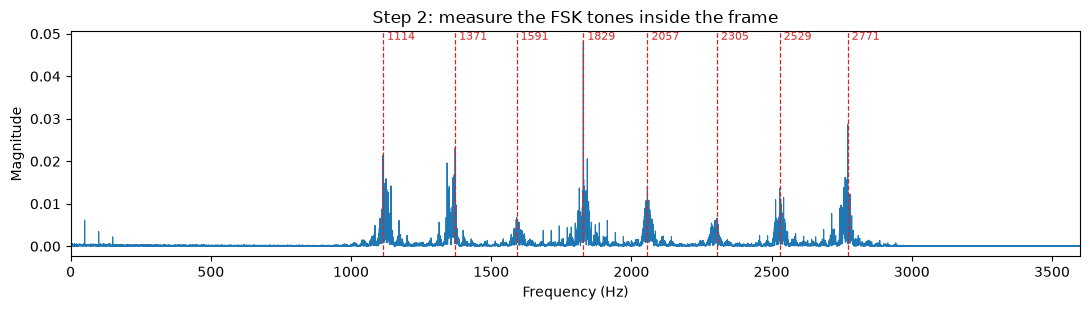

In [12]:
# 2. Measure the tones inside the data region and compare them with 2.11.
payload_window = (secret_burst.start_sample / secret_rate,
                  secret_burst.end_sample / secret_rate)

f, m = ac.spectrum(secret, secret_rate, seconds=payload_window)
measured = np.sort(ac.find_peaks(f, m, count=ac.TONE_COUNT,
                                 min_hz=500, max_hz=3600, min_separation_hz=100))
measured_base = float(measured[0])
measured_spacing = float(np.mean(np.diff(measured)))

print("tones   ", ", ".join(f"{p:.1f}" for p in measured), "Hz")
print(f"base     {measured_base:.1f} Hz")
print(f"spacing  {measured_spacing:.1f} Hz "
      f"(spread {np.diff(measured).std():.1f} Hz)")

tone_figure = ac.plot_spectrum(
    secret, secret_rate, seconds=payload_window, max_hz=3600, mark_hz=measured,
    title="Step 2: measure the FSK tones inside the frame")


best symbol duration 35.00 ms   (score 100.0%)
8-FSK   base 1114.3 Hz   spacing 236.73 Hz   symbol 35.00 ms
51 bytes, 100.0% printable
message     'WELL DONE. THE AIR WAS THE ONLY NETWORK YOU NEEDED.'


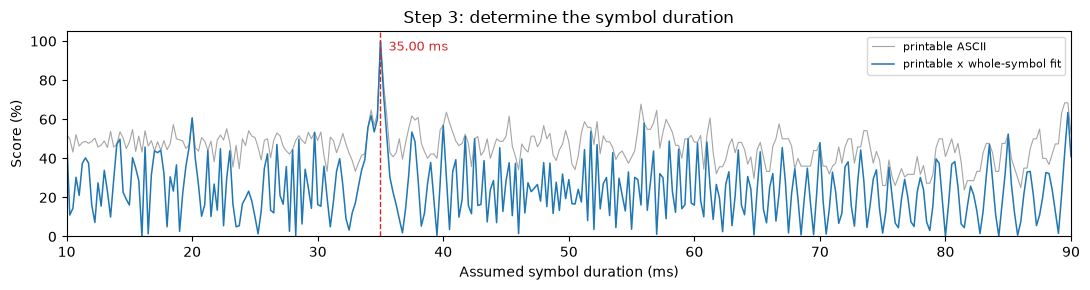

In [13]:
# 3. Determine the symbol duration and decode the data.
secret_search = ac.search_symbol_ms(
    secret, secret_rate, base_hz=measured_base, spacing_hz=measured_spacing,
    burst=secret_burst, low_ms=10.0, high_ms=90.0, step_ms=0.25)

secret_search_figure = ac.plot_search(
    secret_search, title="Step 3: determine the symbol duration")
secret_search.describe()


The recovered message brings together three kinds of measurement: correlation locates the frame, spectral analysis identifies its tones, and the timing search establishes its symbol duration. Together, they turn a continuous recording into a sequence of symbols that can be interpreted as text.

A practical receiver usually supports a predefined set of communication modes rather than searching freely for every parameter. A robust header can identify the selected MCS and payload length, allowing the receiver to apply the appropriate settings directly. The search in this notebook makes those otherwise shared assumptions visible and shows why they matter.

Keep the measured values available for the exercise below. Notebook 02.13 then applies the same framing and detection ideas to a live acoustic link between two devices.


---

### 12.8 Hands-On Exercise

<div class="alert alert-block alert-info">Fill in the responses and save this notebook. See the <a href="../../03_Assignments/Submission-Guidelines.md">submission guidelines</a> for how to submit your work.</div>

Use the figures and detector outputs as evidence in the answers. Connect each observation to the receiver operation responsible for it, and include measured values where requested.


**Explain the function of the up-chirp, data region, and down-chirp in the frame. What does the down-chirp replace, and when might an explicit length field be preferable?**

- Up-chirp: a known rising sound that marks the start of the message. The receiver finds it with cross-correlation and knows exactly where the data begins.
- Data region (payload): the actual message, sent as 8-FSK tones.
- Down-chirp: a known falling sound that marks the end of the message.

The down-chirp replaces a length field, a header that tells the receiver how long the message is. A length field is better if the end marker could be missed, for example because of noise or echoes. It is also better if the receiver should know the message size in advance, for example to prepare memory or to stop listening at the right time. A length field also avoids the extra time needed to send the down-chirp.

**Using the symbol-duration experiment in 12.6, explain how an incorrect duration affects the analysis windows and tone energies. Which evidence identifies the correct duration in this experiment?**

If the duration is wrong, the receiver's windows don't match the real symbols, and the error grows with every symbol. A window then contains parts of two different tones, so the strongest tone doesn't stand out clearly anymore, and wrong tones are picked.

| Assumed duration | Tone margin | Whole-symbol fit | Decoded text |
|---|---|---|---|
| 25 ms | 83% | 0.60 | gibberish |
| 40 ms | 95% | 1.00 | 'PRACTICE FRAME' |
| 55 ms | 74% | 0.27 | gibberish |

40 ms is correct because:

1. In every window, one tone is clearly the strongest (95%).
2. The data region fits exactly a whole number of symbols (fit 1.00).
3. The text is readable.

**Report the complete decoding chain for `secret_message.wav`: the two chirp positions, the eight tone frequencies, the symbol duration, and the decoded message.**

| Step | Result |
|---|---|
| Up-chirp (start) | at **1.500 s** (match 0.92) |
| Down-chirp (end) | at **6.960 s** (match 0.92) |
| Eight tone frequencies | **1114.3, 1371.4, 1590.5, 1828.6, 2057.1, 2305.3, 2528.6, 2771.4 Hz** (spacing about 236.7 Hz) |
| Symbol duration | **35.00 ms** (8-FSK, 3 bits per symbol) |
| Decoded message | **"WELL DONE. THE AIR WAS THE ONLY NETWORK YOU NEEDED."** |

In [24]:
from ipywidgets import FloatRangeSlider

secret, secret_rate = ac.load_wav(ACOUSTIC_ASSETS / "secret_message.wav")
secret_duration = len(secret) / secret_rate
print(f"{secret_duration:.2f} s at {secret_rate} Hz")
display(Audio(secret, rate=secret_rate))

def make_secret_figure(window):
    first = max(0, int(round(window[0] * secret_rate)))
    last = min(len(secret), int(round(window[1] * secret_rate)))
    piece = secret[first:last]
    time = np.arange(first, last) / secret_rate
    figure, (wave_axis, spectrum_axis) = plt.subplots(2, 1, figsize=(11, 6.0))

    wave_axis.plot(time, piece, linewidth=0.4, color="tab:blue")
    wave_axis.set_xlabel("Time (s)")
    wave_axis.set_ylabel("Amplitude")
    wave_axis.set_title("Waveform of the selected window")
    if window[1] > window[0]:
        wave_axis.set_xlim(window)
    wave_axis.margins(x=0)

    if len(piece) >= 16:
        frequencies, magnitude = ac.spectrum(piece, secret_rate)
        band = frequencies <= 3600
        spectrum_axis.plot(frequencies[band], magnitude[band],
                           linewidth=0.8, color="tab:blue")
    else:
        spectrum_axis.text(0.5, 0.5, "Select a wider time window to show the spectrum.",
                           transform=spectrum_axis.transAxes, ha="center", va="center")
    spectrum_axis.set_xlim(0, 3600)
    spectrum_axis.set_xlabel("Frequency (Hz)")
    spectrum_axis.set_ylabel("Magnitude")
    spectrum_axis.set_title("Spectrum of the selected window")

    figure.suptitle(f"secret_message.wav   {window[0]:.2f} s to {window[1]:.2f} s")
    figure.tight_layout()
    return figure

secret_slider = FloatRangeSlider(min=0.0, max=round(secret_duration, 2), step=0.05,
                                 value=[0.0, round(secret_duration, 2)], readout_format=".2f",
                                 description="Window (s)", continuous_update=False, style=WIDE)
display(secret_slider)


8.41 s at 48000 Hz


FloatRangeSlider(value=(0.0, 8.41), continuous_update=False, description='Window (s)', max=8.41, step=0.05, st…

In [20]:
# 1. Find the two chirps (start and end of the frame)
burst = ac.find_burst(secret, secret_rate)

# 2. Find the eight tone frequencies inside the data region
window = (burst.start_sample / secret_rate, burst.end_sample / secret_rate)
f, m = ac.spectrum(secret, secret_rate, seconds=window)
tones = np.sort(ac.find_peaks(f, m, count=ac.TONE_COUNT,
                              min_hz=500, max_hz=3600, min_separation_hz=100))

# 3. Find the symbol duration and decode the message
result = ac.search_symbol_ms(secret, secret_rate, base_hz=float(tones[0]),
                             spacing_hz=float(np.mean(np.diff(tones))),
                             burst=burst, low_ms=10.0, high_ms=90.0, step_ms=0.25)
result.describe()

best symbol duration 35.00 ms   (score 100.0%)
8-FSK   base 1114.3 Hz   spacing 236.73 Hz   symbol 35.00 ms
51 bytes, 100.0% printable
message     'WELL DONE. THE AIR WAS THE ONLY NETWORK YOU NEEDED.'


**OPTIONAL: Have all tasks in this notebook been read and understood? Are there any shortcomings, missing parts, or sections that should be improved?**

Please help the teaching team improve the notebook by identifying any unclear tasks or explanations and suggesting improvements.

(answer here)
